# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Muskan
**Roll Number:** AP24110011709
**Date:** 09/10/2006

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:* A 70/30 split has higher entropy than a 90/10 split because
the classes are evenly divided in 70/30 split. it is hard to guess the correct label. because in 90/10 one is more dominating split.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [3]:
import math
p_yes = 8 / 14
p_no = 6 / 14

parent_entropy = -(
    p_yes * math.log2(p_yes) +
    p_no * math.log2(p_no)
)
left_entropy = 0
p_yes_right = 2 / 8
p_no_right = 6 / 8

right_entropy = -(
    p_yes_right * math.log2(p_yes_right) +
    p_no_right * math.log2(p_no_right)
)
weighted_entropy = (
    (6 / 14) * left_entropy +
    (8 / 14) * right_entropy
)

information_gain = parent_entropy - weighted_entropy

print("Parent Entropy:", round(parent_entropy, 4))
print("Left Child Entropy:", round(left_entropy, 4))
print("Right Child Entropy:", round(right_entropy, 4))
print("Weighted Child Entropy:", round(weighted_entropy, 4))
print("Information Gain:", round(information_gain, 4))

Parent Entropy: 0.9852
Left Child Entropy: 0
Right Child Entropy: 0.8113
Weighted Child Entropy: 0.4636
Information Gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [5]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [6]:
for attribute in ["Outlook", "Temperature", "Humidity"]:
    print(attribute, ":", round(info_gain(tennis, attribute), 4))

attributes = ["Outlook", "Temperature", "Humidity"]
best_root = max(attributes, key=lambda a: info_gain(tennis, a))
print("\nBest root attribute:", best_root)

for value in tennis[best_root].unique():
    branch = tennis[tennis[best_root] == value]
    print(f"\nBranch: {value}")

    print(branch)

    remaining = [a for a in attributes if a != best_root]
    for attribute in remaining:
        print(attribute, ":", round(info_gain(branch, attribute), 4))

Outlook : 0.2467
Temperature : 0.0292
Humidity : 0.1518

Best root attribute: Outlook

Branch: Sunny
   Outlook Temperature Humidity    Wind Play
0    Sunny         Hot     High    Weak   No
1    Sunny         Hot     High  Strong   No
7    Sunny        Mild     High    Weak   No
8    Sunny        Cool   Normal    Weak  Yes
10   Sunny        Mild   Normal  Strong  Yes
Temperature : 0.571
Humidity : 0.971

Branch: Overcast
     Outlook Temperature Humidity    Wind Play
2   Overcast         Hot     High    Weak  Yes
6   Overcast        Cool   Normal  Strong  Yes
11  Overcast        Mild     High  Strong  Yes
12  Overcast         Hot   Normal    Weak  Yes
Temperature : 0.0
Humidity : 0.0

Branch: Rain
   Outlook Temperature Humidity    Wind Play
3     Rain        Mild     High    Weak  Yes
4     Rain        Cool   Normal    Weak  Yes
5     Rain        Cool   Normal  Strong   No
9     Rain        Mild   Normal    Weak  Yes
13    Rain        Mild     High  Strong   No
Temperature : 0.02
Hum

**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:* A pure branch contains only one class, so its entropy is zero. No further split is needed because the prediction is already certain.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


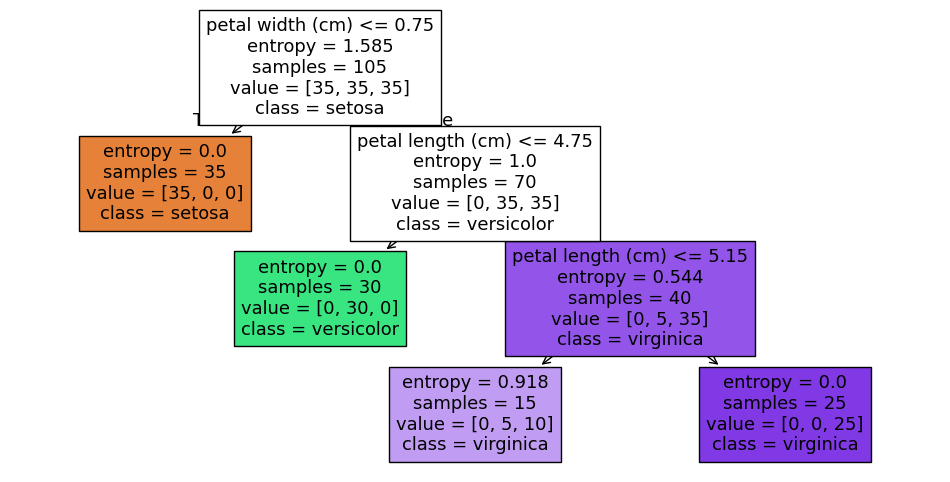

In [7]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


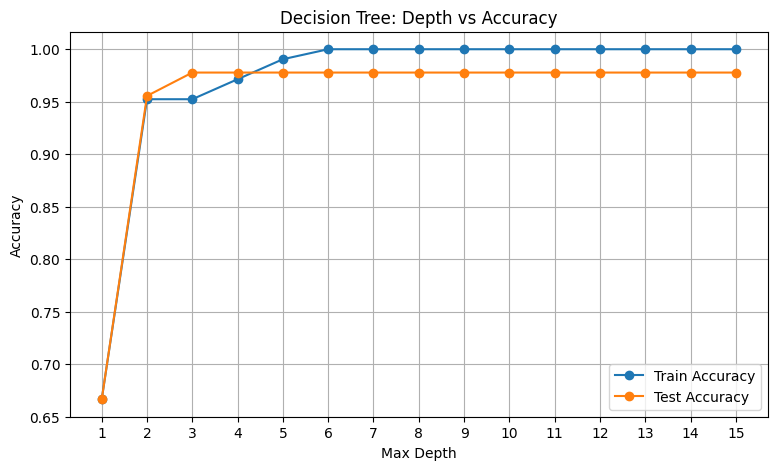

Best depth: 3
Best test accuracy: 0.9778


In [8]:
# Write your answer here

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

depths = range(1, 16)
train_accuracies = []
test_accuracies = []

for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracies.append(accuracy_score(y_train, train_pred))
    test_accuracies.append(accuracy_score(y_test, test_pred))

plt.figure(figsize=(9, 5))
plt.plot(depths, train_accuracies, marker='o', label='Train Accuracy')
plt.plot(depths, test_accuracies, marker='o', label='Test Accuracy')

plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Depth vs Accuracy')
plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)
plt.show()

best_depth = depths[
    list(test_accuracies).index(max(test_accuracies))
]

print("Best depth:", best_depth)
print("Best test accuracy:", round(max(test_accuracies), 4))


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*
max_depth, K in KNN, and polynomial degree all control how complex a model is. If the value is too low, the model may miss patterns (underfitting). If it is too high, it may learn noise (overfitting). The goal is to find the right balance.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Test accuracy: 0.8814814814814815
Max depth 3: Test accuracy = 0.5296
Max depth 6: Test accuracy = 0.8537
Max depth 10: Test accuracy = 0.8796


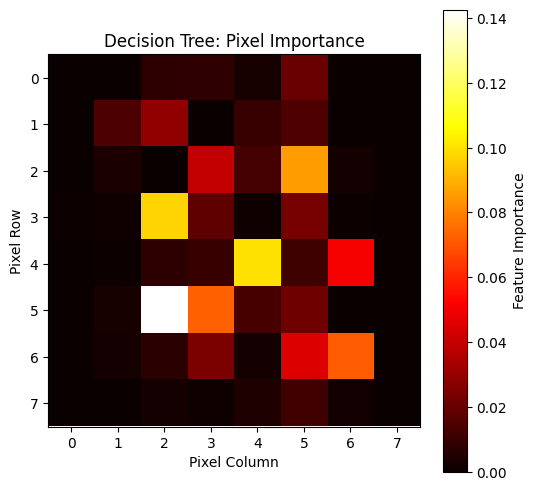

Most important pixel (row, column): (np.int64(5), np.int64(2))


In [10]:
# Write your answer here

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)

pred = tree.predict(Xd_test)
print("Test accuracy:", accuracy_score(yd_test, pred))
for depth in [3, 6, 10]:
    model = DecisionTreeClassifier(
        criterion='entropy',
        max_depth=depth,
        random_state=1
    )
    model.fit(Xd_train, yd_train)
    pred = model.predict(Xd_test)
    print(f"Max depth {depth}: Test accuracy = {accuracy_score(yd_test, pred):.4f}")

importance = tree.feature_importances_.reshape(8, 8)

plt.figure(figsize=(6, 6))
plt.imshow(importance, cmap='hot')
plt.colorbar(label='Feature Importance')
plt.title('Decision Tree: Pixel Importance')
plt.xlabel('Pixel Column')
plt.ylabel('Pixel Row')
plt.show()
print("Most important pixel (row, column):",
      divmod(importance.argmax(), 8))


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*  Decision trees do not need scaling because they split data based on feature values rather than distances. The importance map shows which pixels the tree relies on most to recognize handwritten digits


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [11]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [12]:
# Write your answer here

from sklearn.tree import DecisionTreeClassifier, export_text

# 1. Train the decision tree
tree = DecisionTreeClassifier(
    criterion='entropy',
    random_state=1
)
tree.fit(X_text, labels)

# 2. Print the decision tree
print("Decision Tree:")
print(export_text(tree, feature_names=vocab))

# 3. Predict the topic of new sentences
new_sentences = [
    'the striker scored a goal',
    'the phone battery is fast'  # Your own sentence
]

X_new = np.array([
    to_vector(sentence, vocab)
    for sentence in new_sentences
])

predictions = tree.predict(X_new)

for sentence, prediction in zip(new_sentences, predictions):
    print(f"Sentence: {sentence}")
    print(f"Predicted topic: {prediction}")


Decision Tree:
|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

Sentence: the striker scored a goal
Predicted topic: sports
Sentence: the phone battery is fast
Predicted topic: sports


**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:* If we add more sentences for each topic, the split words may change. This shows that a tree trained on very little data may not always make reliable predictions.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
